In [1]:
import anndata as ad
import scanpy as sc
import pandas as pd
import numpy as np
import scipy.sparse as sp
import SPACEL
from SPACEL import Scube

In [2]:
import scanpy as sc 

import pandas as pd
refAD = sc.read_h5ad("rep2_spot.h5ad")
queryAD = sc.read_h5ad("rep1_spot.h5ad")
refDF = pd.read_csv("valis_output/ref_cell_positions.csv")
queryDF = pd.read_csv("valis_output/moving_valisOutput.csv")
refDF.index = refDF.Cell_Num.astype(str)
queryDF.index = queryDF.Cell_Num.astype(str)
print(refAD.obs.shape, queryAD.obs.shape, refDF.shape, queryDF.shape)
refAD.obs['New_X'] = refDF.loc[refAD.obs.Cell_Num.astype(str),'New_X']
refAD.obs['New_Y'] = refDF.loc[refAD.obs.Cell_Num.astype(str),'New_Y']

queryAD.obs['New_X'] = queryDF.loc[queryAD.obs.Cell_Num.astype(str),'Valis_X']
queryAD.obs['New_Y'] = queryDF.loc[queryAD.obs.Cell_Num.astype(str),'Valis_Y']
sc.pp.normalize_total(refAD, target_sum=1e2)
sc.pp.normalize_total(queryAD, target_sum=1e2)
sc.pp.log1p(refAD)
sc.pp.log1p(queryAD)

sc.pp.scale(refAD)
sc.pp.scale(queryAD)

(3801, 12) (3184, 12) (3801, 7) (3184, 10)


In [3]:
refAD.obsm['initAlign'] = refAD.obs[['New_X','New_Y']].values
queryAD.obsm['initAlign'] = queryAD.obs[['New_X','New_Y']].values






In [4]:
cols = ['Smooth muscle cells_percentage',
    'Fibroblast_percentage',
    'Atrial cardiomyocytes_percentage',
    'Cardiomyocytes_percentage',
    'Endothelium_percentage',
    'Epicardium_percentage',
    'Schwan progenitors_percentage',
    'Ventricular cardiomyocytes_percentage']

# Remove '_percentage' to get cell type names
cell_types = [col.replace('_percentage', '') for col in cols]

# Find the column with the maximum value for each row and assign as 'Ground Truth'
queryAD.obs['CellType'] = queryAD.obs[cols].idxmax(axis=1).str.replace('_percentage', '').astype('category')
refAD.obs['CellType'] = refAD.obs[cols].idxmax(axis=1).str.replace('_percentage', '').astype('category')


In [5]:
from SPACEL import Splane, Spoint

Splane.utils.add_cell_type_composition(refAD, celltype_anno=refAD.obs['CellType'])
Splane.utils.add_cell_type_composition(queryAD, celltype_anno=queryAD.obs['CellType'])

adata_list = [refAD, queryAD]

splane_model = Splane.init_model(adata_list, n_clusters=10, k=2, gnn_dropout=0.8, use_gpu=True)


Global seed set to 0


Setting global seed: 42
Calculating cell type weights...
Generating GNN inputs...
Calculating largest eigenvalue of normalized graph Laplacian...


/home/adyprat/anaconda3/envs/SPACEL/lib/python3.8/site-packages/SPACEL/Splane/pygcn_utils.py:11: RuntimeWarning: divide by zero encountered in power
  d = sp.diags(np.power(np.array(adj.sum(1)), -1).flatten(), 0)


Calculating Chebyshev polynomials up to order 2...


In [1]:
import sklearn as sk 
sk.__version__

'1.3.2'

In [6]:
splane_model.train(d_l=0.2)
splane_model.identify_spatial_domain()

Setting the weight of similarity loss to 2.089


The best epoch 155 total loss=-2.678 g loss=-2.526 d loss=0.763 d acc=0.551 simi loss=-0.992 db loss=0.598:  70%|███████   | 210/300 [01:00<00:25,  3.47it/s]

Stop trainning because of loss convergence


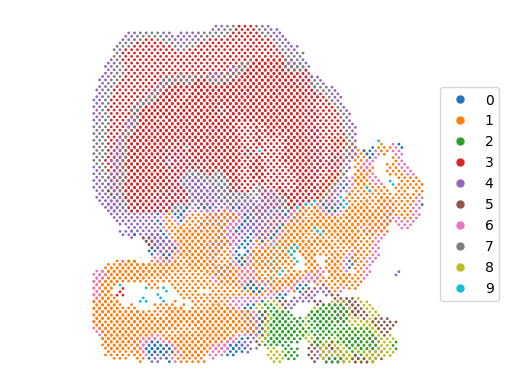

In [7]:
Scube.plot_stacked_slices(adata_list,spatial_key='spatial',cluster_key='spatial_domain')

In [8]:
Scube.align(adata_list,
      cluster_key='spatial_domain', 
      n_neighbors = 24, 
      raw_loc_key = 'initAlign',
      n_threads=10,
      p=2,
      a=1,
      write_loc_path='Scube_outputs/aligned_coordinates.csv'
     )

Start alignment...
Alignment slice 1 to 0
Runtime: 16.494466543197632 s


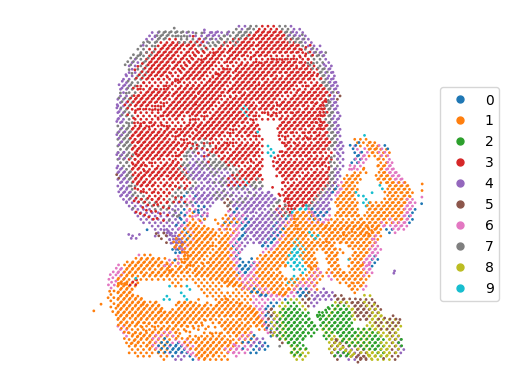

In [9]:
Scube.plot_stacked_slices(adata_list,spatial_key='spatial_aligned',cluster_key='spatial_domain')


In [10]:
import numpy as np
from scipy.spatial import cKDTree

# Get coordinates from refAD and queryAD using the 'spatial_aligned' key
ref_coords = refAD.obsm['spatial_aligned']
query_coords = queryAD.obsm['spatial_aligned']

# Get cell types
ref_celltypes = refAD.obs['CellType'].values
query_celltypes = queryAD.obs['CellType'].values

# For each query cell, find the nearest ref cell and compare CellType
tree = cKDTree(ref_coords)
dists, idxs = tree.query(query_coords, k=1)

# Compare cell types
matches = query_celltypes == ref_celltypes[idxs]

# Optionally, print or summarize the results
print(f"Number of matches: {np.sum(matches)} / {len(matches)}")
print(f"Match percentage: {np.mean(matches)*100:.2f}%")

# If you want to see which ones matched/mismatched:
queryAD.obs['NearestRefCellType_aligned'] = ref_celltypes[idxs]
queryAD.obs['CellTypeMatch_aligned'] = matches


Number of matches: 1779 / 3184
Match percentage: 55.87%


In [16]:
refAD.obsm['X_SPACEL_spatial'] = refAD.obsm['spatial_aligned'].copy()
refAD.write_h5ad('ref_SPACEL.h5ad')
queryAD.obsm['X_SPACEL_spatial'] = queryAD.obsm['spatial_aligned'].copy()
queryAD.write_h5ad('query_SPACEL.h5ad')

In [75]:
import numpy as np
from scipy.spatial import cKDTree

# Get coordinates from refAD and queryAD using the 'spatial_aligned' key
ref_coords = refAD.obsm['spatial_aligned']
query_coords = queryAD.obsm['spatial_aligned']

# Get cell types
ref_celltypes = refAD.obs['spatial_domain'].values
query_celltypes = queryAD.obs['spatial_domain'].values

# For each query cell, find the nearest ref cell and compare CellType
tree = cKDTree(ref_coords)
dists, idxs = tree.query(query_coords, k=1)

# Compare cell types
matches = query_celltypes == ref_celltypes[idxs]

# Optionally, print or summarize the results
print(f"Number of matches: {np.sum(matches)} / {len(matches)}")
print(f"Match percentage: {np.mean(matches)*100:.2f}%")

# If you want to see which ones matched/mismatched:
queryAD.obs['NearestRefCellType_aligned'] = ref_celltypes[idxs]
queryAD.obs['CellTypeMatch_aligned'] = matches


Number of matches: 2344 / 3184
Match percentage: 73.62%


In [73]:
import numpy as np
from scipy.spatial import cKDTree

# Get coordinates from refAD and queryAD using the 'spatial_aligned' key
ref_coords = refAD.obsm['initAlign']
query_coords = queryAD.obsm['initAlign']

# Get cell types
ref_celltypes = refAD.obs['CellType'].values
query_celltypes = queryAD.obs['CellType'].values

# For each query cell, find the nearest ref cell and compare CellType
tree = cKDTree(ref_coords)
dists, idxs = tree.query(query_coords, k=1)

# Compare cell types
matches = query_celltypes == ref_celltypes[idxs]

# Optionally, print or summarize the results
print(f"Number of matches: {np.sum(matches)} / {len(matches)}")
print(f"Match percentage: {np.mean(matches)*100:.2f}%")

# If you want to see which ones matched/mismatched:
queryAD.obs['NearestRefCellType_aligned'] = ref_celltypes[idxs]
queryAD.obs['CellTypeMatch_aligned'] = matches


Number of matches: 1834 / 3184
Match percentage: 57.60%
